In [1]:
!nvidia-smi -L
!nvidia-smi

GPU 0: Tesla T4 (UUID: GPU-8f7abc33-86e9-f14f-ec5e-0c190b4ff575)
Thu Oct 22 19:16:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |       

In [2]:
!pip install -q transformers datasets scikit-learn pandas

import time, gc
import pandas as pd, torch
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW

# HW4.a settings, unchanged
SEED, SLICE, MAX_LENGTH, LR = 2733, 733, 128, 2e-5
device = torch.device("cuda")
GPU = torch.cuda.get_device_name(0)
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3
print(f"GPU: {GPU} | VRAM: {VRAM_GB:.1f} GB")

# Same data and 70% train split as HW4.a
df = load_dataset("EleutherAI/twitter-sentiment", split="train").to_pandas()
work_df = df.iloc[SLICE:SLICE + 5000]
train_df, _ = train_test_split(work_df, test_size=0.30, random_state=SEED, stratify=work_df["label"])

tok = BertTokenizer.from_pretrained("bert-base-uncased")
enc = tok(train_df["text"].astype(str).tolist(), padding="max_length",
          truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
train_dataset = TensorDataset(enc["input_ids"], enc["attention_mask"],
                              torch.tensor(train_df["label"].astype(int).tolist()))
N = len(train_dataset)

def run_epoch(bs):
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2).to(device)
    opt = AdamW(model.parameters(), lr=LR)
    loader = DataLoader(train_dataset, batch_size=bs, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    torch.cuda.reset_peak_memory_stats()
    model.train()
    torch.cuda.synchronize(); t0 = time.perf_counter()
    for ids, mask, y in loader:
        ids, mask, y = ids.to(device), mask.to(device), y.to(device)
        opt.zero_grad()
        model(input_ids=ids, attention_mask=mask, labels=y).loss.backward()
        opt.step()
    torch.cuda.synchronize()
    epoch_time = time.perf_counter() - t0
    peak = torch.cuda.max_memory_allocated() / 1024**3
    del model, opt
    return epoch_time, peak

results, bs, oom_bs = [], 8, None
while bs <= N:
    oom = False
    try:
        t, peak = run_epoch(bs)
    except torch.cuda.OutOfMemoryError:
        oom = True
    gc.collect(); torch.cuda.empty_cache()
    if oom:
        oom_bs = bs
        print(f"batch {bs}: OUT OF MEMORY")
        break
    results.append({"gpu": GPU, "vram_gb": round(VRAM_GB, 1), "batch_size": bs,
                    "samples_per_sec": N / t, "peak_mem_gb": peak, "epoch_time_s": t})
    print(f"batch {bs}: {N/t:.1f} samples/s | peak {peak:.2f} GB | epoch {t:.1f} s")
    bs *= 2

res = pd.DataFrame(results)
res.to_csv(f"partA_{GPU.replace(' ', '_')}.csv", index=False)
print(f"\nLargest batch that runs: {res.batch_size.max()} | first OOM: {oom_bs}")
print(res.round(2).to_string(index=False))

GPU: Tesla T4 | VRAM: 14.6 GB


README.md:   0%|          | 0.00/501 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  107MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  691kB            

...

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


batch 128: 49.1 samples/s | peak 10.95 GB | epoch 71.3 s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


batch 256: OUT OF MEMORY

Largest batch that runs: 128 | first OOM: 256
     gpu  vram_gb  batch_size  samples_per_sec  peak_mem_gb  epoch_time_s
Tesla T4     14.6           8            41.00         2.09         85.37
Tesla T4     14.6          16            43.71         2.48         80.07
Tesla T4     14.6          32            47.57         3.73         73.58
Tesla T4     14.6          64            48.59         6.11         72.03
Tesla T4     14.6         128            49.07        10.95         71.33


## Part A — Batch Scaling to the Memory Wall (Tesla T4, 14.6 GB)

HW4.a fine-tune unchanged: bert-base-uncased, fp32, AdamW lr 2e-5, max length 128, 3,500 training rows (733–5732, 70% split, SEED 2733). One epoch timed per batch size.

| Batch size | Throughput (samples/s) | Peak memory (GB) | Time per epoch (s) |
|---:|---:|---:|---:|
| 8 | 41.00 | 2.09 | 85.37 |
| 16 | 43.71 | 2.48 | 80.07 |
| 32 | 47.57 | 3.73 | 73.58 |
| 64 | 48.59 | 6.11 | 72.03 |
| 128 | 49.07 | 10.95 | 71.33 |
| 256 | OOM | — | — |

**Largest batch that runs on the T4: 128** (batch 256 runs out of memory).

Throughput stops improving meaningfully after **batch 32**: going to 64 adds only 2.1%, and 128 adds a further 1.0%, while peak memory almost triples (3.73 → 10.95 GB). The T4 is already compute-bound at batch 32, so larger batches use more memory without speeding up training.

Sanity check: batch 32 peak memory (3.73 GB) and epoch time (73.6 s ≈ 221.63 s / 3) match the HW4.a baseline.

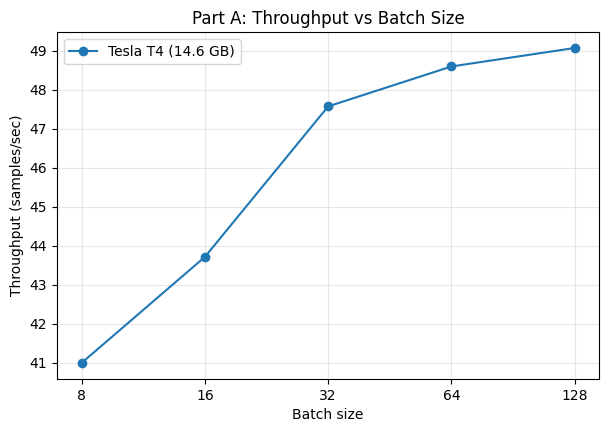

In [3]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

dfs = [pd.read_csv(f) for f in sorted(glob.glob("partA_*.csv"))]
all_bs = sorted(set().union(*[set(d.batch_size) for d in dfs]))

plt.figure(figsize=(7, 4.5))
for d in dfs:
    plt.plot(d.batch_size, d.samples_per_sec, marker="o",
             label=f"{d.gpu.iloc[0]} ({d.vram_gb.iloc[0]} GB)")
plt.xscale("log", base=2)
plt.xticks(all_bs, [str(b) for b in all_bs])
plt.xlabel("Batch size")
plt.ylabel("Throughput (samples/sec)")
plt.title("Part A: Throughput vs Batch Size")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("partA_throughput.png", dpi=150, bbox_inches="tight")
plt.show()